# BERT Fine-tuning on IMDB — Training & Validation
### Fine-tuning bert-base-uncased for binary sentiment classification
**Dataset:** IMDB (49,578 reviews after cleaning) | **Split:** 70/15/15  
**Epochs:** 3 | **Batch size:** 16 | **Learning rate:** 2e-5 | **Device:** GPU (T4)

## Step 1 — Imports & Setup

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install transformers datasets # Install the essential libraries for modeling and data processing

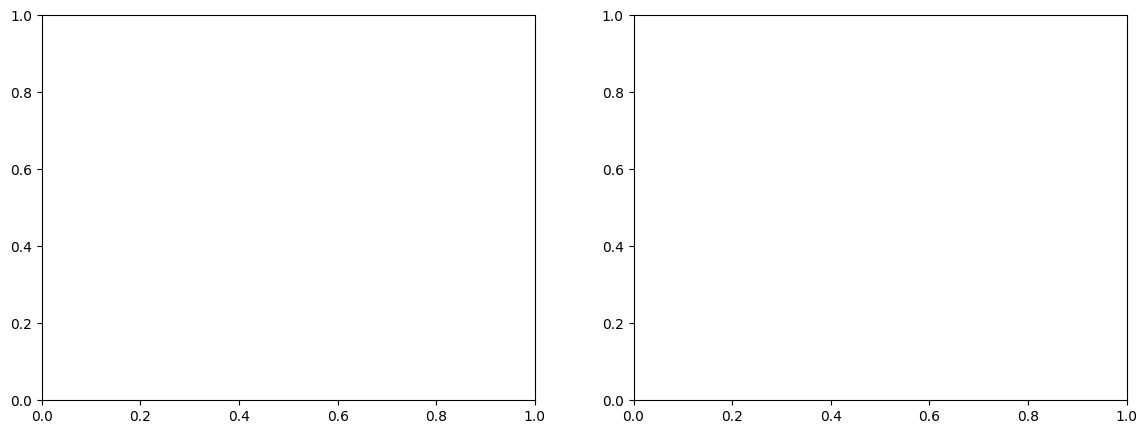

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

## Step 2 — Data Loading and BERT Model Initialization
We load the already tokenized dataset, set up the DataLoaders for training and evaluation, and download the pre-trained BERT model, adapting its classification head for 2 classes.

In [ ]:
from datasets import load_from_disk
from transformers import BertForSequenceClassification
from torch.utils.data import DataLoader
import torch

# Path to tokenized dataset in Google Drive
SAVE_PATH  = "/content/drive/MyDrive/Licenta/tokenized_imdb"
MODEL_NAME = "bert-base-uncased" # Pre-trained BERT variant — uncased means all text is lowercased
NUM_LABELS = 2 # Binary classification: 0 = Negative, 1 = Positive
DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Use GPU (T4 in Colab) if available, otherwise fall back to CPU

# Load dataset
dataset = load_from_disk(SAVE_PATH)

# DataLoaders
BATCH_SIZE = 16  # number of samples processed per forward pass

# shuffle=True for train: ensures different batch order each epoch
# shuffle=False for val/test: order doesn't affect evaluation results
train_loader = DataLoader(dataset["train"], batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(dataset["val"],   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(dataset["test"],  batch_size=BATCH_SIZE, shuffle=False)

# Load model
model = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_LABELS) # num_labels=2 replaces BERT's MLM head with a 2-class classifier
model = model.to(DEVICE)

print(f"Device     : {DEVICE}")
print(f"Train batches : {len(train_loader)}")
print("Model ready!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device     : cuda
Train batches : 2169
Model ready!


## Step 3 — Optimizer and Scheduler Setup (Learning Rate)
We define how the model weights will be updated during training. We use AdamW along with a scheduler that gradually increases the learning rate at the beginning (warmup), then decreases it linearly.

In [ ]:
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW  # Using AdamW directly from PyTorch

# Hyperparameters
NUM_EPOCHS    = 3 # Total number of passes through the entire dataset
LEARNING_RATE = 2e-5 # Standard learning rate for BERT fine-tuning
WEIGHT_DECAY  = 0.01 # Penalty to prevent overfitting

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

# Scheduler
total_steps  = len(train_loader) * NUM_EPOCHS
# Set the first 10% of steps for warmup (helps with training stability at the start)
warmup_steps = int(0.1 * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

print(f"Epochs        : {NUM_EPOCHS}")
print(f"Learning rate : {LEARNING_RATE}")
print(f"Total steps   : {total_steps}")
print(f"Warmup steps  : {warmup_steps}")
print("Optimizer and scheduler ready!")

Epochs        : 3
Learning rate : 2e-05
Total steps   : 6507
Warmup steps  : 650
Optimizer and scheduler ready!


## Step 4 — Training Loop and Validation
The model passes through the data, calculates its error (Loss), performs backpropagation, and adjusts its weights. At the end of each epoch, it is evaluated on the validation set, and the best model is automatically saved to Drive.

In [ ]:
import time

def evaluate(model, loader, device):
    """
    Function to calculate loss and accuracy on a given dataloader.
    """
    model.eval() # Put the model in evaluation mode (disables Dropout, etc.)
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad(): # Disable gradient calculation to save memory and time
        for batch in loader:
            # Move tensors to the correct device (GPU/CPU)
            input_ids      = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels         = batch["labels"].to(device)

            # Forward pass: get the raw predictions (logits)
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()
            # Choose the class with the highest probability
            preds       = torch.argmax(outputs.logits, dim=1)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)

    avg_loss = total_loss / len(loader)
    accuracy = correct / total
    return avg_loss, accuracy

# Dictionary to store the history of metrics (useful for plotting later)
history = {
    "train_loss": [], "train_acc": [],
    "val_loss":   [], "val_acc":  [],
}

best_val_acc  = 0.0
MODEL_SAVE_PATH = "/content/drive/MyDrive/Licenta/best_model"

print("Starting training...\n")

for epoch in range(NUM_EPOCHS):
    model.train() # Activate training mode
    total_loss, correct, total = 0, 0, 0
    start_time = time.time()

    for batch_idx, batch in enumerate(train_loader):
        # 1. Extract data from the batch
        input_ids      = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels         = batch["labels"].to(DEVICE)

        # 2. Clear previously accumulated gradients
        optimizer.zero_grad()

        # 3. Forward pass (Pass data through the model)
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        # 4. Backward pass (Calculate gradients)
        loss.backward()

        # Gradient clipping: Prevents the "exploding gradients" problem
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # 5. Update weights and learning rate
        optimizer.step()
        scheduler.step()

        # Calculate live metrics for training
        total_loss += loss.item()
        preds       = torch.argmax(outputs.logits, dim=1)
        correct    += (preds == labels).sum().item()
        total      += labels.size(0)

        # Print progress every 100 batches
        if (batch_idx + 1) % 100 == 0:
            print(f"  Epoch {epoch+1} | Batch {batch_idx+1}/{len(train_loader)} "
                  f"| Loss: {loss.item():.4f}")

    # Calculate final metrics for the epoch
    train_loss = total_loss / len(train_loader)
    train_acc  = correct / total
    val_loss, val_acc = evaluate(model, val_loader, DEVICE)
    elapsed    = time.time() - start_time

    # Save data to history for plotting
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"\nResult Epoch {epoch+1}/{NUM_EPOCHS} — {elapsed:.0f}s")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")

    # Save the model only if it achieved a better accuracy on the validation set
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        model.save_pretrained(MODEL_SAVE_PATH)
        print(f"  ✅ Best model saved! Val Acc: {val_acc:.4f}")

    print()

print(f"Training complete! Best Validation Accuracy: {best_val_acc:.4f}")

Starting training...

  Epoch 1 | Batch 100/2169 | Loss: 0.7766
  Epoch 1 | Batch 200/2169 | Loss: 0.4361
  Epoch 1 | Batch 300/2169 | Loss: 0.1829
  Epoch 1 | Batch 400/2169 | Loss: 0.4607
  Epoch 1 | Batch 500/2169 | Loss: 0.1994
  Epoch 1 | Batch 600/2169 | Loss: 0.3809
  Epoch 1 | Batch 700/2169 | Loss: 0.5077
  Epoch 1 | Batch 800/2169 | Loss: 0.2110
  Epoch 1 | Batch 900/2169 | Loss: 0.1013
  Epoch 1 | Batch 1000/2169 | Loss: 0.0299
  Epoch 1 | Batch 1100/2169 | Loss: 0.0887
  Epoch 1 | Batch 1200/2169 | Loss: 0.1992
  Epoch 1 | Batch 1300/2169 | Loss: 0.3315
  Epoch 1 | Batch 1400/2169 | Loss: 0.3434
  Epoch 1 | Batch 1500/2169 | Loss: 0.2251
  Epoch 1 | Batch 1600/2169 | Loss: 0.0308
  Epoch 1 | Batch 1700/2169 | Loss: 0.0508
  Epoch 1 | Batch 1800/2169 | Loss: 0.0398
  Epoch 1 | Batch 1900/2169 | Loss: 0.0396
  Epoch 1 | Batch 2000/2169 | Loss: 0.1676
  Epoch 1 | Batch 2100/2169 | Loss: 0.1905

Epoch 1/3 — 3753s
  Train Loss: 0.2770 | Train Acc: 0.8835
  Val   Loss: 0.1652 | V

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved! Val Acc: 0.9379

  Epoch 2 | Batch 100/2169 | Loss: 0.0759
  Epoch 2 | Batch 200/2169 | Loss: 0.0087
  Epoch 2 | Batch 300/2169 | Loss: 0.2202
  Epoch 2 | Batch 400/2169 | Loss: 0.3959
  Epoch 2 | Batch 500/2169 | Loss: 0.0034
  Epoch 2 | Batch 600/2169 | Loss: 0.0052
  Epoch 2 | Batch 700/2169 | Loss: 0.0164
  Epoch 2 | Batch 800/2169 | Loss: 0.2380
  Epoch 2 | Batch 900/2169 | Loss: 0.0100
  Epoch 2 | Batch 1000/2169 | Loss: 0.0116
  Epoch 2 | Batch 1100/2169 | Loss: 0.2026
  Epoch 2 | Batch 1200/2169 | Loss: 0.0020
  Epoch 2 | Batch 1300/2169 | Loss: 0.0070
  Epoch 2 | Batch 1400/2169 | Loss: 0.0061
  Epoch 2 | Batch 1500/2169 | Loss: 0.0102
  Epoch 2 | Batch 1600/2169 | Loss: 0.1478
  Epoch 2 | Batch 1700/2169 | Loss: 0.0134
  Epoch 2 | Batch 1800/2169 | Loss: 0.3464
  Epoch 2 | Batch 1900/2169 | Loss: 0.2913
  Epoch 2 | Batch 2000/2169 | Loss: 0.0041
  Epoch 2 | Batch 2100/2169 | Loss: 0.0047

Epoch 2/3 — 3773s
  Train Loss: 0.1425 | Train Acc: 0.9584
  Val  

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  ✅ Best model saved! Val Acc: 0.9462

Training complete! Best Val Accuracy: 0.9462


## Step 5 — Generating Performance Plots
We save the training history in a plot to observe how the loss function and accuracy evolved over the epochs.

In [ ]:
import matplotlib.pyplot as plt

# Values from our training run
history = {
    "train_loss": [0.2770, 0.1425, 0.0746],
    "val_loss":   [0.1652, 0.2563, 0.2540],
    "train_acc":  [0.8835, 0.9584, 0.9817],
    "val_acc":    [0.9379, 0.9369, 0.9462],
}

NUM_EPOCHS = 3


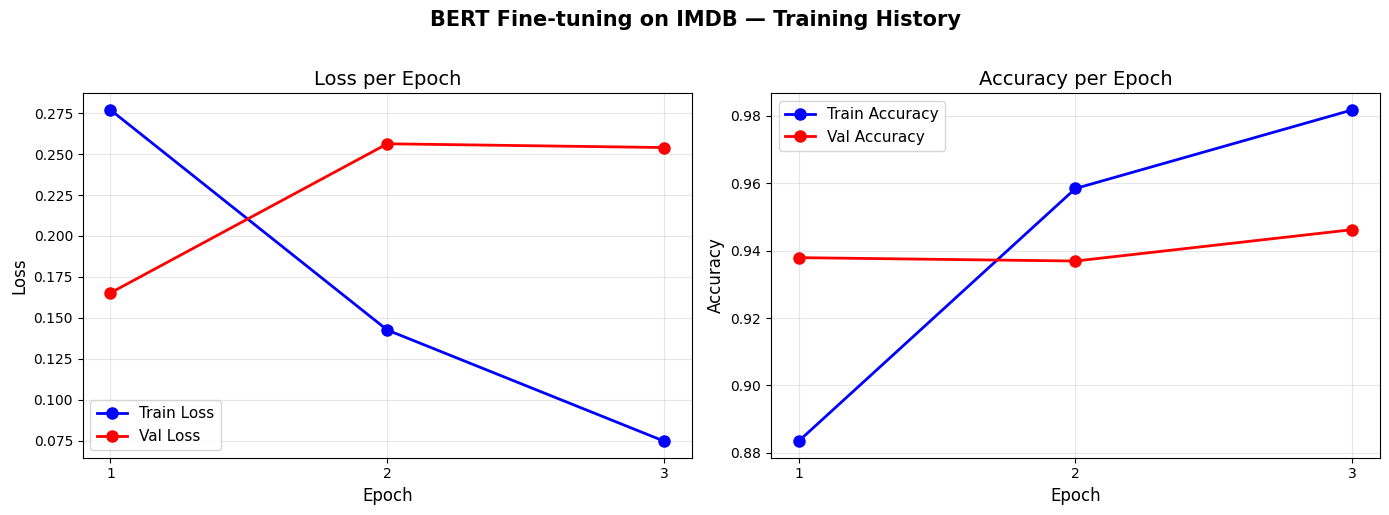

Plot saved to Drive!


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, NUM_EPOCHS + 1)

# --- Plot 1: Loss ---
axes[0].plot(epochs, history["train_loss"],
             "b-o", label="Train Loss", linewidth=2, markersize=8)
axes[0].plot(epochs, history["val_loss"],
             "r-o", label="Val Loss",   linewidth=2, markersize=8)
axes[0].set_title("Loss per Epoch",  fontsize=14)
axes[0].set_xlabel("Epoch",          fontsize=12)
axes[0].set_ylabel("Loss",           fontsize=12)
axes[0].legend(fontsize=11)
axes[0].set_xticks(epochs)
axes[0].grid(True, alpha=0.3)

# --- Plot 2: Accuracy ---
axes[1].plot(epochs, history["train_acc"],
             "b-o", label="Train Accuracy", linewidth=2, markersize=8)
axes[1].plot(epochs, history["val_acc"],
             "r-o", label="Val Accuracy",   linewidth=2, markersize=8)
axes[1].set_title("Accuracy per Epoch", fontsize=14)
axes[1].set_xlabel("Epoch",             fontsize=12)
axes[1].set_ylabel("Accuracy",          fontsize=12)
axes[1].legend(fontsize=11)
axes[1].set_xticks(epochs)
axes[1].grid(True, alpha=0.3)

plt.suptitle("BERT Fine-tuning on IMDB — Training History",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/training_history.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved to Drive!")